# Bengaluru residential prices: what actually drives the number on the board?

**A data-science case study on 13,320 property listings — cleaning, EDA, and a price model.**

---

### The short version

| Question | Answer |
|---|---|
| What explains asking price? | Built-up area, above everything else. Location is second. |
| How much does location matter? | The same square foot ranges from **₹2,885** (Attibele) to **₹13,719** (Rajaji Nagar) — a **4.8× spread**. |
| What does an extra bedroom cost? | A 3BHK asks **51% more** than a 2BHK in the same locality, but offers only **37% more floor area** — about **10% is pure configuration premium**. |
| Can we predict price? | Yes, to **₹27 lakh MAE** on held-out data (R² 0.68) versus ₹56 lakh for a naive median guess. |
| Where does it fail? | Above roughly ₹150 lakh it systematically under-predicts. Asking prices, not transaction prices. |

*Dataset: Bengaluru house price listings (public, 13,320 rows × 9 columns). Currency throughout is ₹ lakh.*

## 1. The question

A buyer in Bengaluru is told a 3BHK in Whitefield costs ₹1.2 crore. A seller in Jayanagar is told their flat is worth ₹90 lakh. Neither number arrives with an explanation.

This notebook asks two things:

1. **What actually moves the asking price** — and by how much?
2. **Can a model price a listing well enough to be useful** as a sanity check on a quote?

The second question only matters if the first is answered honestly, so the analysis spends real effort on data quality before touching a model.

In [1]:
%matplotlib inline
import json, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                              HistGradientBoostingRegressor)
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import r2_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
pd.set_option("display.width", 120, "display.max_columns", 30)

SEED = 42
np.random.seed(SEED)

INK, ACCENT, ACCENT2, MUTED = "#1B2A41", "#C8553D", "#2A6F97", "#8C9BA5"
sns.set_theme(style="whitegrid", rc={
    "figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": "#D8DEE4",
    "axes.labelcolor": INK, "text.color": INK, "xtick.color": INK, "ytick.color": INK,
    "font.family": "DejaVu Sans", "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.labelsize": 10.5, "figure.dpi": 110, "savefig.dpi": 150,
    "savefig.bbox": "tight", "grid.color": "#EAEFF3"})

import os
FIG = "figures"; os.makedirs(FIG, exist_ok=True)
print("environment ready")

environment ready


## 2. The data, and an honest audit

The raw file is the well-known Bengaluru listings dataset: one row per property, with area type, availability, locality, configuration, total area, bathrooms, balconies, and asking price.

Before any chart, the audit below decides how much of it is trustworthy.

In [2]:
raw = pd.read_csv("data/Bengaluru_House_Data.csv")
raw.columns = [c.strip().lower() for c in raw.columns]
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

13,320 rows x 9 columns


,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [3]:
audit_tbl = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing_%": (raw.isna().mean() * 100).round(1),
    "unique": raw.nunique(),
})
print("duplicate rows:", raw.duplicated().sum())
audit_tbl

duplicate rows: 529


,dtype,missing_%,unique
area_type,str,0.0,4
availability,str,0.0,81
location,str,0.0,1305
size,str,0.1,31
society,str,41.3,2688
total_sqft,str,0.0,2117
bath,float64,0.5,19
balcony,float64,4.6,4
price,float64,0.0,1994


Three things stand out and shape everything downstream:

- **`society` is 41% missing** — too sparse to use as a feature, so it is dropped.
- **`total_sqft` is text, not a number.** It contains ranges (`"1000 - 1500"`), and units in metres, yards, acres, cents, guntha and perch.
- **`size` mixes formats** — `"2 BHK"` and `"4 Bedroom"` mean the same thing.

And the numbers themselves contain errors: a 2BHK listed at 600 sq ft, a property with 40 bathrooms. Those are caught by rules below.

## 3. Cleaning: rules, not vibes

Every exclusion is explicit and counted, so the report can state exactly how much data was discarded and why.

In [4]:
UNIT_TO_SQFT = {"sq. meter": 10.7639, "sq. yards": 9.0, "sq. yard": 9.0, "acres": 43560.0,
                "cents": 435.6, "guntha": 1089.0, "perch": 272.25, "grounds": 2400.0}

def parse_sqft(v):
    # Numeric sqft from messy strings; ranges take the midpoint, units are converted.
    if pd.isna(v):
        return np.nan
    s = str(v).strip().lower()
    try:
        return float(s)                       # already numeric
    except ValueError:
        pass
    if "-" in s:                              # "1000 - 1500" -> 1250
        parts = re.findall(r"\d+\.?\d*", s)
        if len(parts) == 2:
            return (float(parts[0]) + float(parts[1])) / 2
    m = re.match(r"([\d.]+)\s*([a-z.\s]+)", s)  # "34.46Sq. Meter" -> 370.9
    if m:
        num, unit = float(m.group(1)), m.group(2).strip()
        for k, f in UNIT_TO_SQFT.items():
            if unit.startswith(k):
                return num * f
    return np.nan

def parse_bhk(v):
    m = re.search(r"(\d+)", str(v)) if pd.notna(v) else None
    return float(m.group(1)) if m else np.nan

# show what the parser is fixing
odd = raw["total_sqft"].astype(str)
odd = odd[~odd.str.fullmatch(r"\d+\.?\d*")]
print(f"{len(odd)} values needed parsing. Sample before -> after:")
pd.DataFrame({"raw": odd.sample(6, random_state=1)}).assign(
    parsed=lambda d: d["raw"].map(parse_sqft).round(1))

247 values needed parsing. Sample before -> after:


,raw,parsed
2998,1446 - 1506,1476.0
13299,2830 - 2882,2856.0
10895,684 - 810,747.0
11650,1140 - 1250,1195.0
4497,2725 - 3250,2987.5
11583,1215 - 1495,1355.0


In [5]:
df = raw.copy()
df["total_sqft"] = df["total_sqft"].map(parse_sqft)
df["bhk"] = df["size"].map(parse_bhk)
df["location"] = df["location"].fillna("Unknown").str.strip()
df["area_type"] = df["area_type"].str.replace(r"\s+", " ", regex=True).str.strip()
df["ready_to_move"] = (df["availability"].astype(str).str.strip() == "Ready To Move").astype(int)

n0 = len(df)
steps = [("raw rows", n0)]

df = df.dropna(subset=["total_sqft", "bhk", "price"]);      steps.append(("unparseable area/config/price", len(df)))
df = df[(df["total_sqft"] >= 300) & (df["total_sqft"] <= 10000)];  steps.append(("area outside 300-10,000 sq ft", len(df)))
df = df[(df["bhk"] >= 1) & (df["bhk"] <= 10)];              steps.append(("BHK outside 1-10", len(df)))
df = df.dropna(subset=["bath"]);                            steps.append(("bathroom count missing", len(df)))
df = df[df["bath"] <= df["bhk"] + 2];                       steps.append(("more bathrooms than rooms allow", len(df)))

df["balcony"] = df["balcony"].fillna(df["balcony"].median())
df["sqft_per_bhk"] = df["total_sqft"] / df["bhk"]
df = df[df["sqft_per_bhk"] >= 300];                         steps.append(("under 300 sq ft per bedroom", len(df)))

df["price_per_sqft"] = df["price"] * 1e5 / df["total_sqft"]
stats = df.groupby("location")["price_per_sqft"].agg(["mean", "std", "count"])
df = df.join(stats, on="location", rsuffix="_loc")
keep = ~((df["count"] >= 10) & ((df["price_per_sqft"] < df["mean"] - 3 * df["std"]) |
                                (df["price_per_sqft"] > df["mean"] + 3 * df["std"])))
df = df[keep].drop(columns=["mean", "std", "count"]);        steps.append(("price/sq ft beyond 3 sd of locality", len(df)))
df = df.drop_duplicates(subset=["location", "total_sqft", "bath", "bhk", "price"])
steps.append(("exact duplicates", len(df)))
df = df.reset_index(drop=True)

funnel = pd.DataFrame(steps, columns=["stage", "rows_remaining"])
funnel["removed"] = funnel["rows_remaining"].shift(1) - funnel["rows_remaining"]
print(f"kept {len(df):,} of {n0:,} rows ({len(df)/n0:.1%})")
funnel = funnel.assign(removed=funnel["removed"].fillna(0)).astype({"rows_remaining": int, "removed": int})
funnel

kept 11,423 of 13,320 rows (85.8%)


,stage,rows_remaining,removed
0,raw rows,13320,0
1,unparseable area/config/price,13304,16
2,"area outside 300-10,000 sq ft",13251,53
3,BHK outside 1-10,13239,12
4,bathroom count missing,13182,57
5,more bathrooms than rooms allow,13167,15
6,under 300 sq ft per bedroom,12446,721
7,price/sq ft beyond 3 sd of locality,12298,148
8,exact duplicates,11423,875


Roughly one row in seven is discarded — the vast majority for physically implausible area-per-bedroom figures, which is exactly where the dataset's data-entry errors concentrate.

One last grouping step: 1,305 distinct locality strings is far too many to encode as-is (most appear once or twice), so localities with fewer than 10 listings are folded into a single `Other` bucket. That trades a little resolution for a lot of stability.

In [6]:
loc_counts = df["location"].value_counts()
rare = loc_counts[loc_counts < 10].index
df["location_grouped"] = df["location"].where(~df["location"].isin(rare), "Other")
df["society"] = df["society"].fillna("Unknown").str.strip()

clean_summary = {
    "raw_rows": int(n0), "final_rows": int(len(df)),
    "dropped_pct": round(100 * (n0 - len(df)) / n0, 1),
    "locations_raw": int(raw["location"].nunique()),
    "locations_grouped": int(df["location_grouped"].nunique()),
    "median_price_lakh": round(float(df["price"].median()), 1),
    "median_ppsf": int(df["price_per_sqft"].median()),
    "median_sqft": int(df["total_sqft"].median()),
}
clean_summary

{'raw_rows': 13320,
 'final_rows': 11423,
 'dropped_pct': 14.2,
 'locations_raw': 1305,
 'locations_grouped': 227,
 'median_price_lakh': 70.0,
 'median_ppsf': 5311,
 'median_sqft': 1305}

## 4. What the data says

### 4.1 Price is skewed, and that matters for modelling

The distribution is heavily right-skewed with a long tail of luxury listings. Modelling `log(price)` rather than price stops those few ₹10-crore properties from dominating the loss function — and makes residuals behave far better.

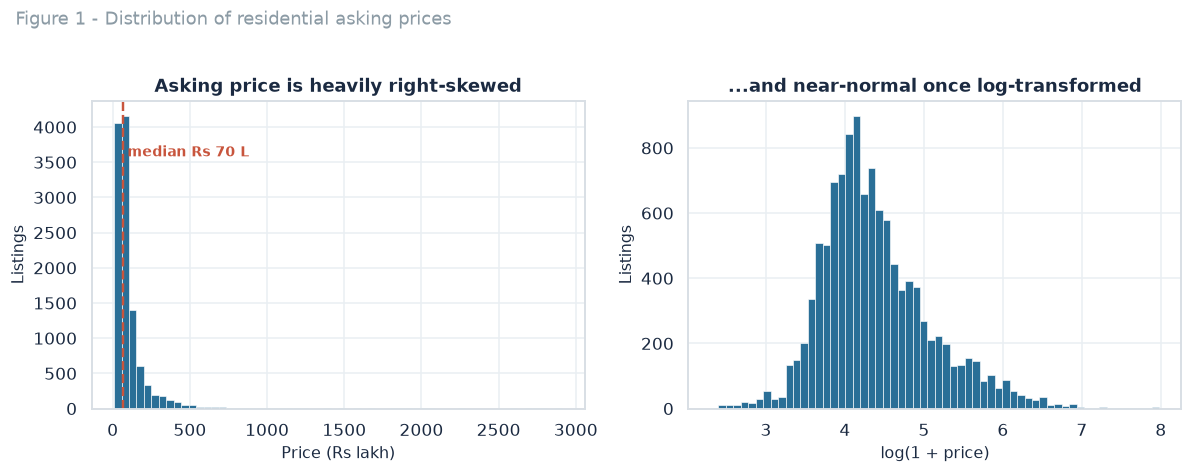

skew before log: 7.58   after: 0.87


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].hist(df["price"], bins=60, color=ACCENT2, edgecolor="white", linewidth=0.4)
ax[0].axvline(df["price"].median(), color=ACCENT, ls="--", lw=1.6)
ax[0].text(df["price"].median() + 25, ax[0].get_ylim()[1] * 0.82,
           f"median Rs {df['price'].median():.0f} L", color=ACCENT, fontsize=9, fontweight="bold")
ax[0].set(title="Asking price is heavily right-skewed", xlabel="Price (Rs lakh)", ylabel="Listings")
ax[1].hist(np.log1p(df["price"]), bins=60, color=ACCENT2, edgecolor="white", linewidth=0.4)
ax[1].set(title="...and near-normal once log-transformed", xlabel="log(1 + price)", ylabel="Listings")
fig.suptitle("Figure 1 - Distribution of residential asking prices", fontsize=12, y=1.02, x=0.02, ha="left", color=MUTED)
fig.tight_layout(); fig.savefig(f"{FIG}/fig1_price_distribution.png"); plt.show()

print(f"skew before log: {df['price'].skew():.2f}   after: {np.log1p(df['price']).skew():.2f}")

### 4.2 Configuration and area type

Each added bedroom steps the price up sharply. Area *type* matters far less than buyers assume — carpet area commands only about a 14% premium per square foot over super built-up area, which is roughly the loading factor itself.

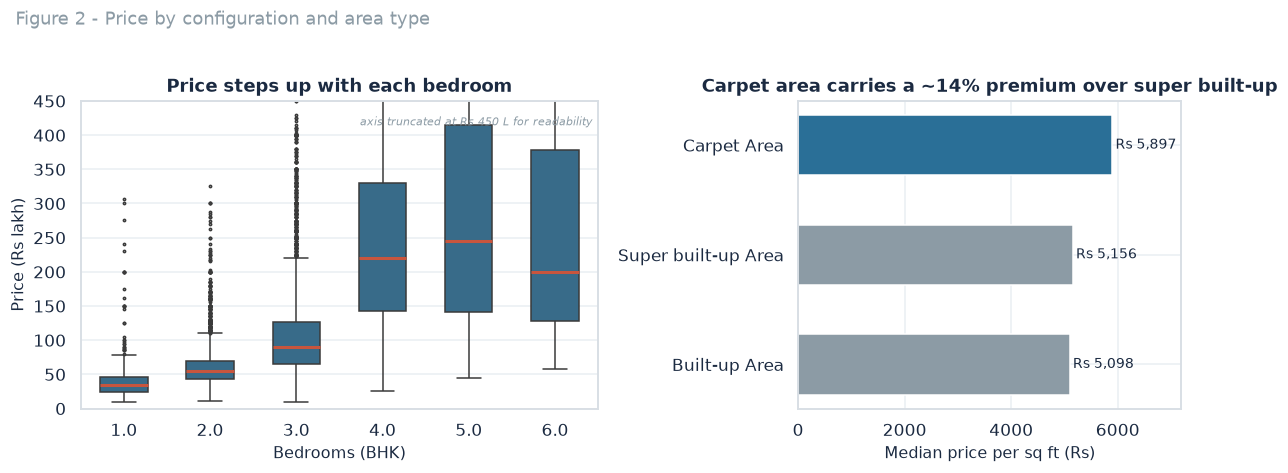

In [8]:
sub = df[df["bhk"].between(1, 6)]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.35, 1]})
sns.boxplot(data=sub, x="bhk", y="price", ax=ax[0], color=ACCENT2, width=0.55, fliersize=1.5,
            linewidth=1, medianprops=dict(color=ACCENT, lw=2))
ax[0].set(title="Price steps up with each bedroom", xlabel="Bedrooms (BHK)", ylabel="Price (Rs lakh)")
ax[0].set_ylim(0, 450)
ax[0].text(0.99, 0.95, "axis truncated at Rs 450 L for readability", transform=ax[0].transAxes,
           ha="right", va="top", fontsize=7.5, color=MUTED, style="italic")

at = (df[df["area_type"].isin(["Built-up Area", "Carpet Area", "Super built-up Area"])]
      .groupby("area_type")["price_per_sqft"].median().sort_values())
ax[1].barh(at.index, at.values, color=[ACCENT2 if i == at.index[-1] else MUTED for i in at.index], height=0.55)
for i, v in enumerate(at.values):
    ax[1].text(v + 60, i, f"Rs {v:,.0f}", va="center", fontsize=9, color=INK)
ax[1].set(title="Carpet area carries a ~14% premium over super built-up",
          xlabel="Median price per sq ft (Rs)", ylabel="")
ax[1].set_xlim(0, at.max() * 1.22)
fig.suptitle("Figure 2 - Price by configuration and area type", fontsize=12, y=1.02, x=0.02, ha="left", color=MUTED)
fig.tight_layout(); fig.savefig(f"{FIG}/fig2_price_by_config.png"); plt.show()

### 4.3 Location is the second-biggest lever

This is the headline finding. The same square foot of built-up area is priced at **₹2,885 in Attibele** and **₹13,719 in Rajaji Nagar** — a 4.8× spread across one city. No other feature in the dataset comes close to that range.

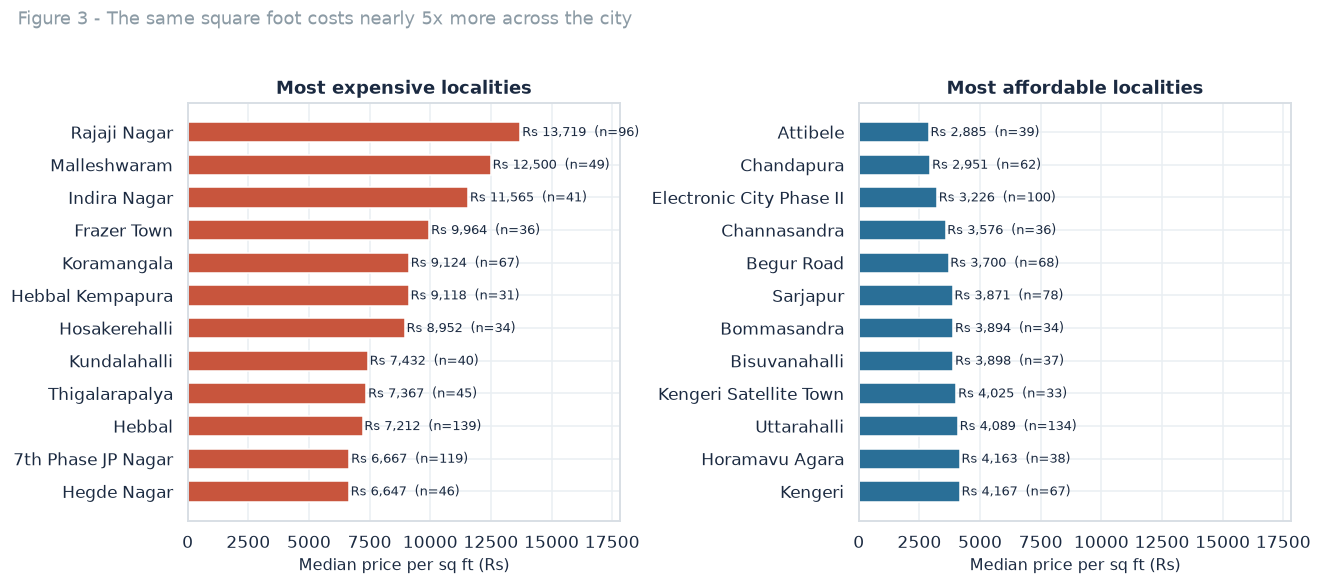

cheapest: Rs 2,885/sqft (Attibele)
priciest: Rs 13,719/sqft (Rajaji Nagar)
ratio: 4.8x


In [9]:
lc = (df.groupby("location_grouped")
        .agg(n=("price", "size"), med_ppsf=("price_per_sqft", "median"), med_price=("price", "median")))
lc = lc[lc["n"] >= 30].sort_values("med_ppsf", ascending=False)
top, bottom = lc.head(12), lc.tail(12).sort_values("med_ppsf")

fig, ax = plt.subplots(1, 2, figsize=(12, 5.2))
for a, d, t, c in [(ax[0], top, "Most expensive localities", ACCENT),
                   (ax[1], bottom, "Most affordable localities", ACCENT2)]:
    a.barh(d.index[::-1], d["med_ppsf"][::-1], color=c, height=0.62)
    for i, (v, n) in enumerate(zip(d["med_ppsf"][::-1], d["n"][::-1])):
        a.text(v + 70, i, f"Rs {v:,.0f}  (n={n})", va="center", fontsize=8.2, color=INK)
    a.set(title=t, xlabel="Median price per sq ft (Rs)")
    a.set_xlim(0, lc["med_ppsf"].max() * 1.3)
fig.suptitle("Figure 3 - The same square foot costs nearly 5x more across the city",
             fontsize=12, y=1.02, x=0.02, ha="left", color=MUTED)
fig.tight_layout(); fig.savefig(f"{FIG}/fig3_locality_premium.png"); plt.show()

print(f"cheapest: Rs {lc['med_ppsf'].min():,.0f}/sqft ({lc['med_ppsf'].idxmin()})")
print(f"priciest: Rs {lc['med_ppsf'].max():,.0f}/sqft ({lc['med_ppsf'].idxmax()})")
print(f"ratio: {lc['med_ppsf'].max()/lc['med_ppsf'].min():.1f}x")

### 4.4 What correlates with what

Built-up area correlates most strongly with price (0.74). Note the near-perfect correlation between bathrooms and bedrooms (0.87) — they carry almost the same information, which is worth remembering when reading feature importance later.

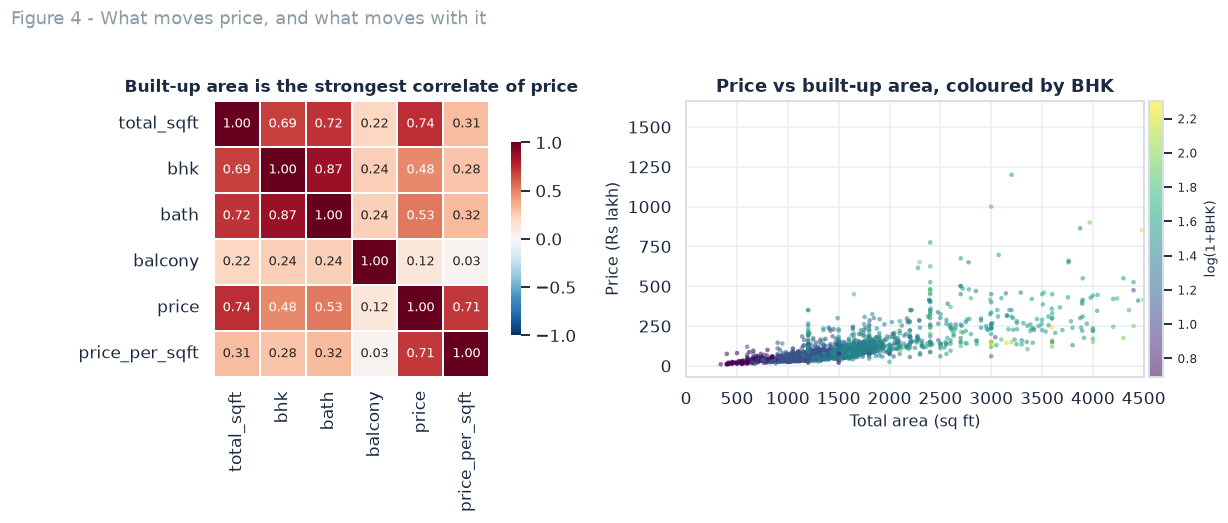

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.4), gridspec_kw={"width_ratios": [1, 1.25]})
corr = df[["total_sqft", "bhk", "bath", "balcony", "price", "price_per_sqft"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True,
            cbar_kws={"shrink": 0.7}, ax=ax[0], annot_kws={"size": 8.5}, linewidths=1, linecolor="white")
ax[0].set_title("Built-up area is the strongest correlate of price", fontsize=11)

samp = df.sample(min(2500, len(df)), random_state=SEED)
sc = ax[1].scatter(samp["total_sqft"], samp["price"], c=np.log1p(samp["bhk"]), cmap="viridis",
                   s=9, alpha=0.55, edgecolors="none")
ax[1].set(title="Price vs built-up area, coloured by BHK", xlabel="Total area (sq ft)", ylabel="Price (Rs lakh)")
ax[1].set_xlim(0, 4500)
cb = fig.colorbar(sc, ax=ax[1], pad=0.01); cb.set_label("log(1+BHK)", fontsize=8.5); cb.ax.tick_params(labelsize=8)
fig.suptitle("Figure 4 - What moves price, and what moves with it", fontsize=12, y=1.02, x=0.02, ha="left", color=MUTED)
fig.tight_layout(); fig.savefig(f"{FIG}/fig4_correlations.png"); plt.show()

## 5. Modelling

**Design choices, and why:**

- **Target:** `log(price)`. Prices span ₹8 lakh to ₹3,600 lakh; the log keeps the loss from being dominated by mansions.
- **Features:** area, BHK, bathrooms, balconies, area-per-bedroom, ready-to-move flag, area type, locality. `society` is excluded — 41% missing.
- **Preprocessing inside a `Pipeline`:** median imputation plus scaling for numeric features, one-hot encoding (with rare categories folded) for the categoricals. Fitting the preprocessor inside the pipeline means **no leakage across CV folds**.
- **Validation:** 5-fold cross-validation on the training split only. The 20% holdout is touched exactly once, at the end.

Five models, from a linear baseline to gradient-boosted trees.

In [11]:
NUM = ["total_sqft", "bhk", "bath", "balcony", "sqft_per_bhk", "ready_to_move"]
CAT = ["area_type", "location_grouped"]
X, y = df[NUM + CAT], df["price"]
y_log = np.log1p(y)

X_tr, X_te, y_tr, y_te = train_test_split(X, y_log, test_size=0.2, random_state=SEED)
y_tr_o, y_te_o = np.expm1(y_tr), np.expm1(y_te)
print(f"train {len(X_tr):,} | holdout {len(X_te):,}")

pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=15, sparse_output=False), CAT),
])

MODELS = {
    "Linear Regression": lambda: LinearRegression(),
    "Ridge (alpha=1)": lambda: Ridge(alpha=1.0),
    "Random Forest": lambda: RandomForestRegressor(n_estimators=120, min_samples_leaf=2,
                                                   max_features="sqrt", n_jobs=-1, random_state=SEED),
    "Gradient Boosting": lambda: GradientBoostingRegressor(n_estimators=120, learning_rate=0.07,
                                                           max_depth=3, subsample=0.9, random_state=SEED),
    "Hist Gradient Boosting": lambda: HistGradientBoostingRegressor(
        max_iter=300, learning_rate=0.07, early_stopping=True,
        validation_fraction=0.1, n_iter_no_change=12, random_state=SEED),
}
print(f"{len(MODELS)} models queued")

train 9,138 | holdout 2,285
5 models queued


In [12]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for name, factory in MODELS.items():
    r2s, maes, rmses = [], [], []
    for tr_idx, va_idx in cv.split(X_tr):
        pipe = Pipeline([("pre", pre), ("model", factory())])
        pipe.fit(X_tr.iloc[tr_idx], y_tr.iloc[tr_idx])
        p_log = pipe.predict(X_tr.iloc[va_idx])
        r2s.append(r2_score(y_tr.iloc[va_idx], p_log))
        pred, act = np.expm1(p_log), np.expm1(y_tr.iloc[va_idx])
        maes.append(np.mean(np.abs(act - pred)))
        rmses.append(np.sqrt(np.mean((act - pred) ** 2)))
    rows.append({"model": name, "r2_log": round(np.mean(r2s), 4), "r2_log_std": round(np.std(r2s), 4),
                 "mae_lakh": round(np.mean(maes), 2), "mae_lakh_std": round(np.std(maes), 2),
                 "rmse_lakh": round(np.mean(rmses), 2)})
    print(f"{name:24s} R2={rows[-1]['r2_log']:.4f}  MAE=Rs {rows[-1]['mae_lakh']:.1f} L")

res_df = pd.DataFrame(rows).sort_values("r2_log", ascending=False)
best_name = res_df.iloc[0]["model"]
res_df

Linear Regression        R2=0.7225  MAE=Rs 39.2 L


Ridge (alpha=1)          R2=0.7225  MAE=Rs 39.3 L


Random Forest            R2=0.7847  MAE=Rs 31.9 L


Gradient Boosting        R2=0.7754  MAE=Rs 32.1 L


Hist Gradient Boosting   R2=0.7911  MAE=Rs 30.6 L


,model,r2_log,r2_log_std,mae_lakh,mae_lakh_std,rmse_lakh
4,Hist Gradient Boosting,0.7911,0.0057,30.57,3.10,82.68
2,Random Forest,0.7847,0.0094,31.95,3.58,94.58
3,Gradient Boosting,0.7754,0.0054,32.11,3.08,86.33
0,Linear Regression,0.7225,0.0128,39.24,3.07,158.63
1,Ridge (alpha=1),0.7225,0.0130,39.30,3.08,160.27


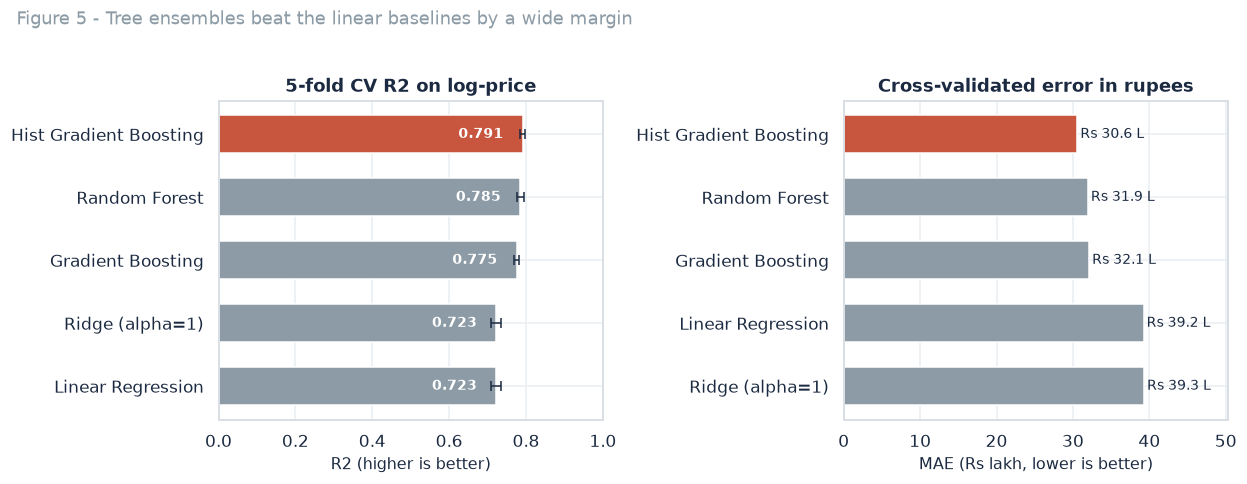

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.3))
d = res_df.sort_values("r2_log")
ax[0].barh(d["model"], d["r2_log"], color=[ACCENT if m == best_name else MUTED for m in d["model"]],
           height=0.6, xerr=d["r2_log_std"], error_kw=dict(ecolor=INK, lw=1, capsize=3))
for i, v in enumerate(d["r2_log"]):
    ax[0].text(v - 0.05, i, f"{v:.3f}", va="center", ha="right", fontsize=9, color="white", fontweight="bold")
ax[0].set(title="5-fold CV R2 on log-price", xlabel="R2 (higher is better)", xlim=(0, 1.0))

d2 = res_df.sort_values("mae_lakh", ascending=False)
ax[1].barh(d2["model"], d2["mae_lakh"], color=[ACCENT if m == best_name else MUTED for m in d2["model"]], height=0.6)
for i, v in enumerate(d2["mae_lakh"]):
    ax[1].text(v + 0.4, i, f"Rs {v:.1f} L", va="center", fontsize=9, color=INK)
ax[1].set(title="Cross-validated error in rupees", xlabel="MAE (Rs lakh, lower is better)",
          xlim=(0, d2["mae_lakh"].max() * 1.28))
fig.suptitle("Figure 5 - Tree ensembles beat the linear baselines by a wide margin",
             fontsize=12, y=1.02, x=0.02, ha="left", color=MUTED)
fig.tight_layout(); fig.savefig(f"{FIG}/fig5_model_comparison.png"); plt.show()

## 6. The chosen model, on data it has never seen

Gradient-boosted trees win on both metrics. The linear baseline is not embarrassing (R² 0.72) but it is consistently ~₹9 lakh worse per listing, which is real money at these price points.

The holdout evaluation below is the number that counts.

In [14]:
best_pipe = Pipeline([("pre", pre), ("model", MODELS[best_name]())]).fit(X_tr, y_tr)
pred = np.expm1(best_pipe.predict(X_te))
ape = np.abs((y_te_o - pred) / y_te_o)
med = float(np.median(y_tr_o))

best = {"model": best_name,
        "r2_log": round(float(r2_score(y_te, np.log1p(pred))), 4),
        "r2_price": round(float(r2_score(y_te_o, pred)), 4),
        "mae_lakh": round(float(np.mean(np.abs(y_te_o - pred))), 2),
        "rmse_lakh": round(float(np.sqrt(np.mean((y_te_o - pred) ** 2))), 2),
        "median_ape": round(float(np.median(ape) * 100), 1),
        "within_10": round(float((ape <= .10).mean() * 100), 1),
        "within_20": round(float((ape <= .20).mean() * 100), 1),
        "within_30": round(float((ape <= .30).mean() * 100), 1)}
baseline = {"mae_lakh": round(float(np.mean(np.abs(y_te_o - med))), 2),
            "r2_price": round(float(r2_score(y_te_o, np.full_like(y_te_o, med))), 4),
            "median_price_lakh": round(med, 1)}

pd.DataFrame([
    {"": "Median guess (baseline)", **{k: baseline[k] for k in ["mae_lakh", "r2_price"]}},
    {"": best_name, **{k: best[k] for k in ["mae_lakh", "r2_price"]}},
]).rename(columns={"mae_lakh": "MAE (Rs L)", "r2_price": "R2 (price)"})

,,MAE (Rs L),R2 (price)
0,Median guess (baseline),55.96,-0.0860
1,Hist Gradient Boosting,27.56,0.6787


In [15]:
print(f"median absolute % error : {best['median_ape']}%")
print(f"within 10% of actual    : {best['within_10']}% of listings")
print(f"within 20% of actual    : {best['within_20']}% of listings")
print(f"within 30% of actual    : {best['within_30']}% of listings")

median absolute % error : 17.7%
within 10% of actual    : 30.8% of listings
within 20% of actual    : 55.3% of listings
within 30% of actual    : 72.6% of listings


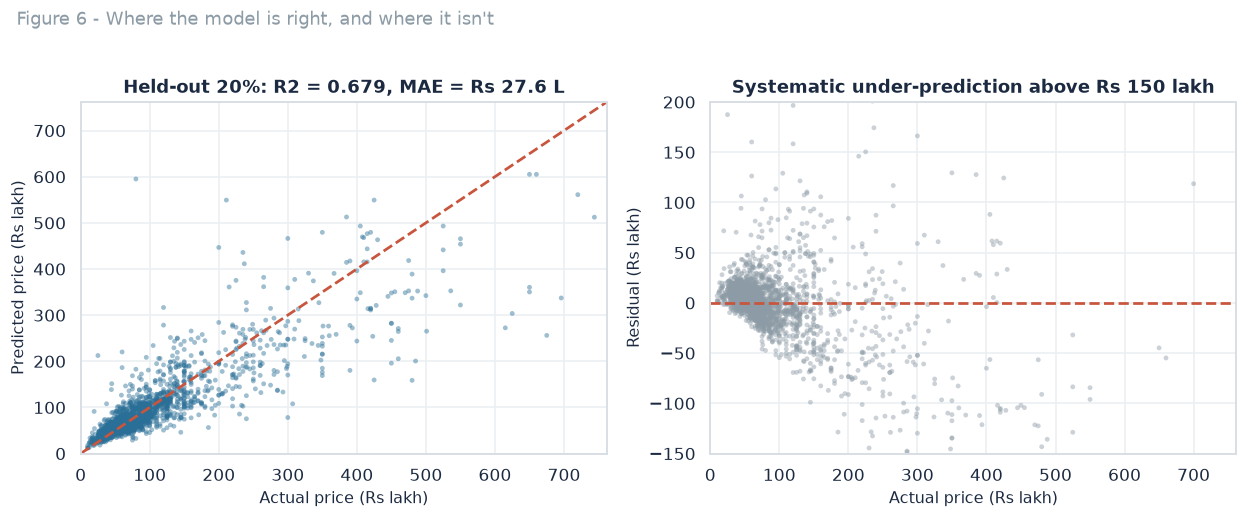

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.6))
lim = [0, float(np.percentile(y_te_o, 99.5))]
ax[0].scatter(y_te_o, pred, s=10, alpha=0.45, color=ACCENT2, edgecolors="none")
ax[0].plot(lim, lim, color=ACCENT, lw=1.8, ls="--")
ax[0].set(xlim=lim, ylim=lim, xlabel="Actual price (Rs lakh)", ylabel="Predicted price (Rs lakh)",
          title=f"Held-out 20%: R2 = {best['r2_price']:.3f}, MAE = Rs {best['mae_lakh']:.1f} L")
ax[1].scatter(y_te_o, pred - y_te_o, s=10, alpha=0.45, color=MUTED, edgecolors="none")
ax[1].axhline(0, color=ACCENT, lw=1.8, ls="--")
ax[1].set(xlim=lim, ylim=(-150, 200), xlabel="Actual price (Rs lakh)", ylabel="Residual (Rs lakh)",
          title="Systematic under-prediction above Rs 150 lakh")
fig.suptitle("Figure 6 - Where the model is right, and where it isn't", fontsize=12, y=1.02, x=0.02, ha="left", color=MUTED)
fig.tight_layout(); fig.savefig(f"{FIG}/fig6_pred_vs_actual.png"); plt.show()

That right-hand panel is the most useful diagnostic in the notebook. Below ₹150 lakh the errors are symmetric — the model is unbiased. Above it, residuals skew negative, meaning the model **under-predicts expensive properties**. Tree ensembles cannot extrapolate beyond the price range they saw in training, and luxury listings are rare and heterogeneous. Any deployment would need a separate treatment for the top end.

### What the model is actually using

Permutation importance on the holdout set: shuffle one feature, measure how much R² falls. It respects interactions and correlated features far better than a raw split-count importance.

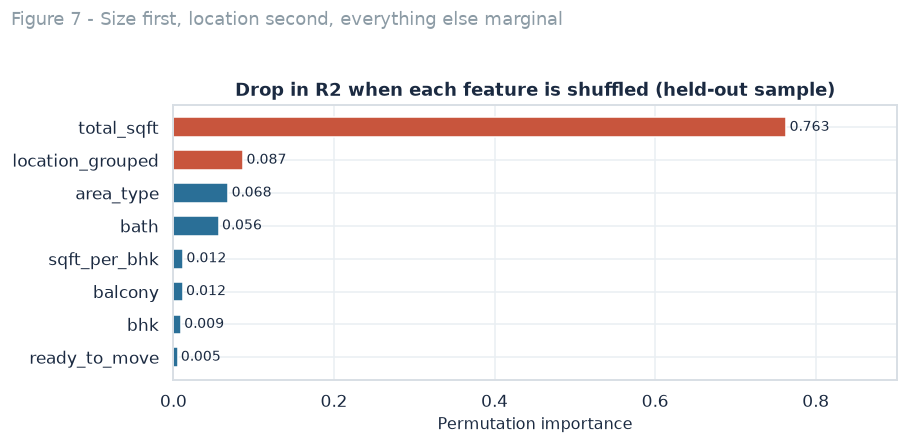

,feature,importance
5,ready_to_move,0.005221
1,bhk,0.009383
3,balcony,0.011709
4,sqft_per_bhk,0.012163
2,bath,0.056467
6,area_type,0.068492
7,location_grouped,0.087024
0,total_sqft,0.763442


In [17]:
samp = X_te.sample(min(500, len(X_te)), random_state=SEED)
pi = permutation_importance(best_pipe, samp, y_te.loc[samp.index], n_repeats=4,
                            random_state=SEED, n_jobs=-1, scoring="r2")
imp = pd.DataFrame({"feature": samp.columns, "importance": pi.importances_mean}).sort_values("importance")

fig, ax = plt.subplots(figsize=(8.4, 3.9))
ax.barh(imp["feature"], imp["importance"],
        color=[ACCENT if f in ("total_sqft", "location_grouped") else ACCENT2 for f in imp["feature"]], height=0.6)
for i, v in enumerate(imp["importance"]):
    ax.text(max(v, 0) + 0.004, i, f"{v:.3f}", va="center", fontsize=9, color=INK)
ax.set(title="Drop in R2 when each feature is shuffled (held-out sample)", xlabel="Permutation importance")
ax.set_xlim(0, max(imp["importance"].max() * 1.18, 0.02))
fig.suptitle("Figure 7 - Size first, location second, everything else marginal",
             fontsize=12, y=1.03, x=0.02, ha="left", color=MUTED)
fig.tight_layout(); fig.savefig(f"{FIG}/fig7_importance.png"); plt.show()
imp

Area dominates. Location comes second — but this understates location's real role: one-hot encoding splits it across ~140 columns, so no *single* column looks important even though the group matters a great deal. `bhk` ranks last because `total_sqft` and `bath` already carry the same signal (remember the 0.87 correlation).

That is the standard caution with permutation importance on one-hot groups: **read it per group, not per column.**

## 7. The numbers a buyer actually wants

Two questions this dataset can answer directly, both of which are more useful than a model score.

In [18]:
both = df[df["bhk"].isin([2, 3])]
ok = both.groupby(["location_grouped", "bhk"])["price"].size().unstack().dropna()
ok = ok[(ok[2] >= 5) & (ok[3] >= 5)].index
bed = (both[both["location_grouped"].isin(ok)]
       .groupby(["location_grouped", "bhk"]).agg(p=("price", "median"), s=("total_sqft", "median"))
       .unstack().dropna())
bed.columns = ["p2", "p3", "s2", "s3"]
bed["price_jump_%"] = ((bed.p3 / bed.p2 - 1) * 100).round(1)
bed["area_jump_%"] = ((bed.s3 / bed.s2 - 1) * 100).round(1)

bed_pct = round(float((bed.p3 / bed.p2 - 1).median()) * 100, 1)
area_pct = round(float((bed.s3 / bed.s2 - 1).median()) * 100, 1)
bed_premium = round(float((bed.p3 / bed.p2).median() / (bed.s3 / bed.s2).median() - 1) * 100, 1)
bed_localities = int(len(bed))

print(f"localities compared: {bed_localities}")
print(f"median 3BHK vs 2BHK price jump : +{bed_pct}%")
print(f"median floor-area jump         : +{area_pct}%")
print(f"premium not explained by area  : +{bed_premium}%")
bed.head(8).round(1)

localities compared: 156
median 3BHK vs 2BHK price jump : +51.3%
median floor-area jump         : +37.0%
premium not explained by area  : +10.5%


,p2,p3,s2,s3,price_jump_%,area_jump_%
location_grouped,,,,,,
1st Phase JP Nagar,87.2,175.0,1202.5,2059.0,100.6,71.2
5th Phase JP Nagar,57.5,75.0,1170.0,1485.0,30.4,26.9
6th Phase JP Nagar,74.5,131.0,1202.5,1645.0,75.8,36.8
7th Phase JP Nagar,61.2,103.5,1080.0,1545.0,69.2,43.1
8th Phase JP Nagar,43.9,60.0,1080.0,1388.0,36.6,28.5
9th Phase JP Nagar,47.5,85.0,1061.5,1571.0,78.9,48.0
Akshaya Nagar,54.5,87.5,1200.0,1662.0,60.6,38.5
Ambalipura,75.0,116.0,1198.0,1690.0,54.7,41.1


A 3BHK in the same locality costs about **51% more** than a 2BHK, while offering **37% more floor area**. So roughly **10% of that jump is configuration premium** — you are paying for the extra bedroom itself, not just the square feet.

### Fair-value check: what the model implies per locality

In [19]:
lc["vs_city"] = (lc["med_ppsf"] / df["price_per_sqft"].median()).round(2)
print("City median: Rs {:,.0f} per sq ft\n".format(df["price_per_sqft"].median()))
lc[["n", "med_ppsf", "med_price", "vs_city"]].head(10).round(1)

City median: Rs 5,312 per sq ft



,n,med_ppsf,med_price,vs_city
location_grouped,,,,
Rajaji Nagar,96,13718.7,250.5,2.6
Malleshwaram,49,12500.0,252.0,2.4
Indira Nagar,41,11564.6,191.0,2.2
Frazer Town,36,9963.6,210.0,1.9
Koramangala,67,9124.1,150.0,1.7
Hebbal Kempapura,31,9117.6,170.0,1.7
Hosakerehalli,34,8952.1,151.5,1.7
Kundalahalli,40,7431.6,97.5,1.4
Thigalarapalya,45,7367.1,152.0,1.4


## 8. Honest limitations

1. **These are asking prices, not transaction prices.** Listed prices in India typically sit above the eventual deal; the model estimates the quote, not the cheque.
2. **No time dimension.** The dataset is a single snapshot (availability dates cluster in 2018), so it cannot capture the market cycle — a serious gap for any current valuation use.
3. **Society is unusable** (41% missing), which removes the single strongest quality signal available in reality — builder reputation, amenities, floor rise.
4. **The luxury tail is unreliable.** Above ₹150 lakh the model under-predicts; that is a structural limit of tree models on sparse extremes, not a tuning problem.
5. **Locality strings are messy.** 1,305 raw spellings collapsed to 227 groups; some genuinely distinct neighbourhoods are merged into `Other`.

### What I would do next

- Add **listing date** and model price trend, not just price level.
- Bring in **external features** — distance to metro/tech parks, school density, floor number, age of building.
- Try **quantile regression** to output a price *range* rather than a point estimate, which is what a buyer actually needs.
- Evaluate on **registered transaction data** (Kaveri/IGR) rather than portal listings.

In [20]:
artifacts = {
    "audit": {"raw_rows": int(n0), "raw_cols": int(raw.shape[1]),
              "missing_pct": {k: round(float(v), 1) for k, v in (raw.isna().mean() * 100).items()},
              "duplicate_rows": int(raw.duplicated().sum()),
              "unique_locations": int(raw["location"].nunique()),
              "unique_societies": int(raw["society"].nunique())},
    "clean": clean_summary,
    "funnel": funnel.to_dict("records"),
    "models": res_df.to_dict("records"),
    "best": best, "baseline": baseline,
    "bedroom_price_jump_pct": bed_pct, "bedroom_area_jump_pct": area_pct,
    "bedroom_config_premium_pct": bed_premium, "bedroom_localities": bed_localities,
    "top_localities": lc.head(8).reset_index().round({"med_ppsf": 0, "med_price": 1}).to_dict("records"),
    "affordable_localities": lc.tail(6).sort_values("med_ppsf").reset_index().round({"med_ppsf": 0, "med_price": 1}).to_dict("records"),
    "cheapest_ppsf": int(round(lc["med_ppsf"].min())), "priciest_ppsf": int(round(lc["med_ppsf"].max())),
    "premium_ratio": round(float(lc["med_ppsf"].max() / lc["med_ppsf"].min()), 1),
    "pct_ready_to_move": round(float(df["ready_to_move"].mean() * 100), 1),
    "pct_super_builtup": round(float((df["area_type"] == "Super built-up Area").mean() * 100), 1),
    "median_ppsf": int(df["price_per_sqft"].median()),
    "importance": imp.sort_values("importance", ascending=False).round(4).to_dict("records"),
    "train_rows": int(len(X_tr)), "test_rows": int(len(X_te)),
    "n_encoded_features": int(best_pipe.named_steps["pre"].transform(X_te.head(2)).shape[1]),
}
with open("metrics.json", "w") as f:
    json.dump(artifacts, f, indent=2)
df.to_csv("clean_bengaluru.csv", index=False)
print("saved metrics.json, clean_bengaluru.csv and 7 figures")
print(json.dumps({k: artifacts[k] for k in ["best", "baseline", "bedroom_config_premium_pct"]}, indent=2))

saved metrics.json, clean_bengaluru.csv and 7 figures
{
  "best": {
    "model": "Hist Gradient Boosting",
    "r2_log": 0.8041,
    "r2_price": 0.6787,
    "mae_lakh": 27.56,
    "rmse_lakh": 65.33,
    "median_ape": 17.7,
    "within_10": 30.8,
    "within_20": 55.3,
    "within_30": 72.6
  },
  "baseline": {
    "mae_lakh": 55.96,
    "r2_price": -0.086,
    "median_price_lakh": 70.0
  },
  "bedroom_config_premium_pct": 10.5
}
